# Predykcje vs maski - zbiór testowy DeepCrack

Szybki podgląd najlepszego checkpointu: obraz, maska prawdziwa, mapa prawdopodobieństwa i nakładka błędów
(**zielony** = TP, **czerwony** = FP, **niebieski** = FN).

In [1]:
import os
from pathlib import Path

# notatnik leży w notebooks/, a ścieżki w configu są względne do katalogu głównego repo
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

import numpy as np
import torch
import matplotlib.pyplot as plt

from crackseg.data import CrackDataset
from crackseg.model import CrackSegModel

MANIFEST = "manifests/manifest.csv"
DATA_DIR = "data/raw/deepcrack"
THRESHOLD = 0.5
SEED = 0
FIG_DIR = Path("outputs/figures")
LOG_TO_MLFLOW = False      # True -> rysunki trafią też jako artefakty do runu MLflow

# najnowszy checkpoint z outputs/<id_eksperymentu>/<id_runu>/checkpoints/
CKPT = max(Path("outputs").glob("*/*/checkpoints/*.ckpt"), key=lambda p: p.stat().st_mtime)
RUN_ID = CKPT.parts[-3]
print("checkpoint:", CKPT)
print("run_id:    ", RUN_ID)

C:\Studia\inz\crack__detection\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


checkpoint: outputs\1\346da2418a2c483cb8de8505168b5461\checkpoints\epoch=45-step=1426.ckpt
run_id:     346da2418a2c483cb8de8505168b5461


In [2]:
model = CrackSegModel.load_from_checkpoint(CKPT, map_location="cpu")
model.eval()                                   # BatchNorm na zapamiętanych statystykach, jak w walidacji
ds = CrackDataset(MANIFEST, DATA_DIR, "test")  # bez transformu = całe obrazy, tak jak w trainer.test
print(model.hparams)
print("obrazów testowych:", len(ds))

"arch":    Unet
"encoder": resnet34
"lr":      0.0003
obrazów testowych: 237


In [3]:
MEAN = np.array([0.485, 0.456, 0.406])
STD = np.array([0.229, 0.224, 0.225])

def denormalize(img: torch.Tensor) -> np.ndarray:
    """(3,H,W) po A.Normalize -> (H,W,3) w [0,1] do wyświetlenia"""
    return np.clip(img.permute(1, 2, 0).numpy() * STD + MEAN, 0, 1)

@torch.no_grad()
def predict(i: int):
    img, mask = ds[i]
    prob = model(img.unsqueeze(0)).sigmoid()[0, 0].numpy()   # logity -> prawdopodobieństwa
    gt = mask[0].numpy().astype(bool)
    pred = prob > THRESHOLD
    return denormalize(img), gt, prob, pred

def dice(gt: np.ndarray, pred: np.ndarray) -> float:
    tp = np.sum(gt & pred)
    fp = np.sum(~gt & pred)
    fn = np.sum(gt & ~pred)
    denom = 2 * tp + fp + fn
    return 1.0 if denom == 0 else 2 * tp / denom      # brak pęknięć i brak predykcji = idealnie

def error_overlay(img: np.ndarray, gt: np.ndarray, pred: np.ndarray) -> np.ndarray:
    out = img.copy()
    out[gt & pred] = (0, 1, 0)      # TP
    out[~gt & pred] = (1, 0, 0)     # FP
    out[gt & ~pred] = (0, 0.4, 1)   # FN
    return out

średni Dice na obraz: 0.819   mediana: 0.861


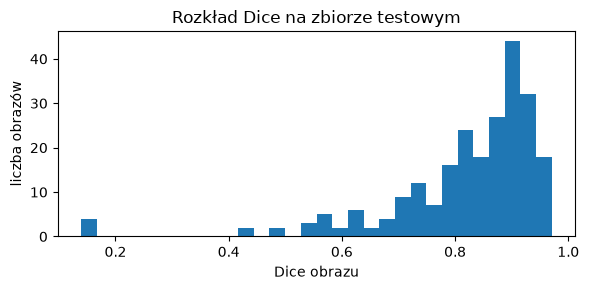

In [4]:
# Dice dla każdego obrazu testowego (na CPU to chwilę trwa)
scores = []
for i in range(len(ds)):
    _, gt, _, pred = predict(i)
    scores.append(dice(gt, pred))
scores = np.array(scores)

print(f"średni Dice na obraz: {scores.mean():.3f}   mediana: {np.median(scores):.3f}")
plt.figure(figsize=(6, 3))
plt.hist(scores, bins=30)
plt.xlabel("Dice obrazu"); plt.ylabel("liczba obrazów"); plt.title("Rozkład Dice na zbiorze testowym")
plt.tight_layout(); plt.show()

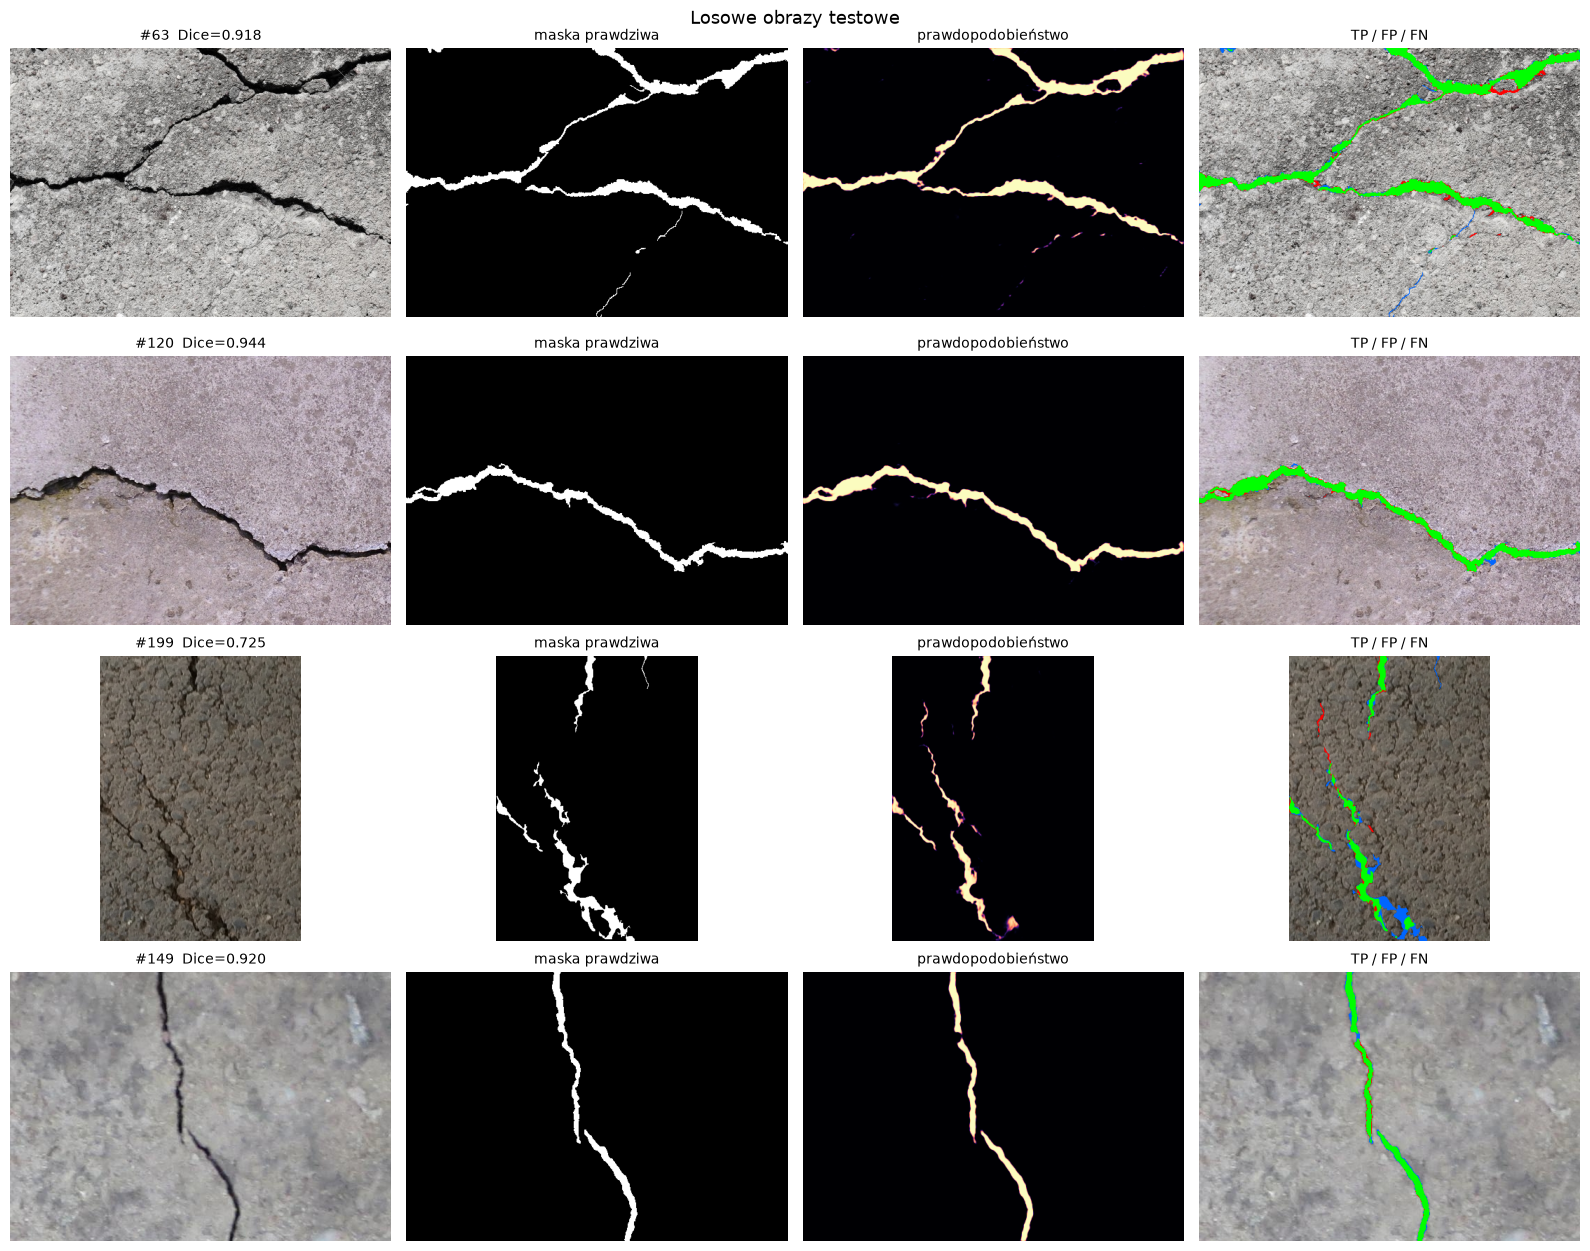

In [5]:
def show_rows(indices, title):
    fig, axes = plt.subplots(len(indices), 4, figsize=(16, 3.2 * len(indices)), squeeze=False)
    for row, i in zip(axes, indices):
        img, gt, prob, pred = predict(i)
        panels = [img, gt, prob, error_overlay(img, gt, pred)]
        names = [f"#{i}  Dice={scores[i]:.3f}", "maska prawdziwa", "prawdopodobieństwo", "TP / FP / FN"]
        for ax, panel, name in zip(row, panels, names):
            if panel is prob:
                im = ax.imshow(panel, vmin=0, vmax=1, cmap="magma")
            else:
                ax.imshow(panel, cmap="gray" if panel.ndim == 2 else None)
            ax.set_title(name, fontsize=10)
            ax.axis("off")
    fig.suptitle(title, fontsize=13)
    fig.tight_layout()
    return fig

FIG_DIR.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(SEED)
random_idx = rng.choice(len(ds), size=4, replace=False)
worst_idx = np.argsort(scores)[:4]

fig_random = show_rows(random_idx, "Losowe obrazy testowe")
fig_random.savefig(FIG_DIR / "predictions_random.png", dpi=150, bbox_inches="tight")
plt.show()

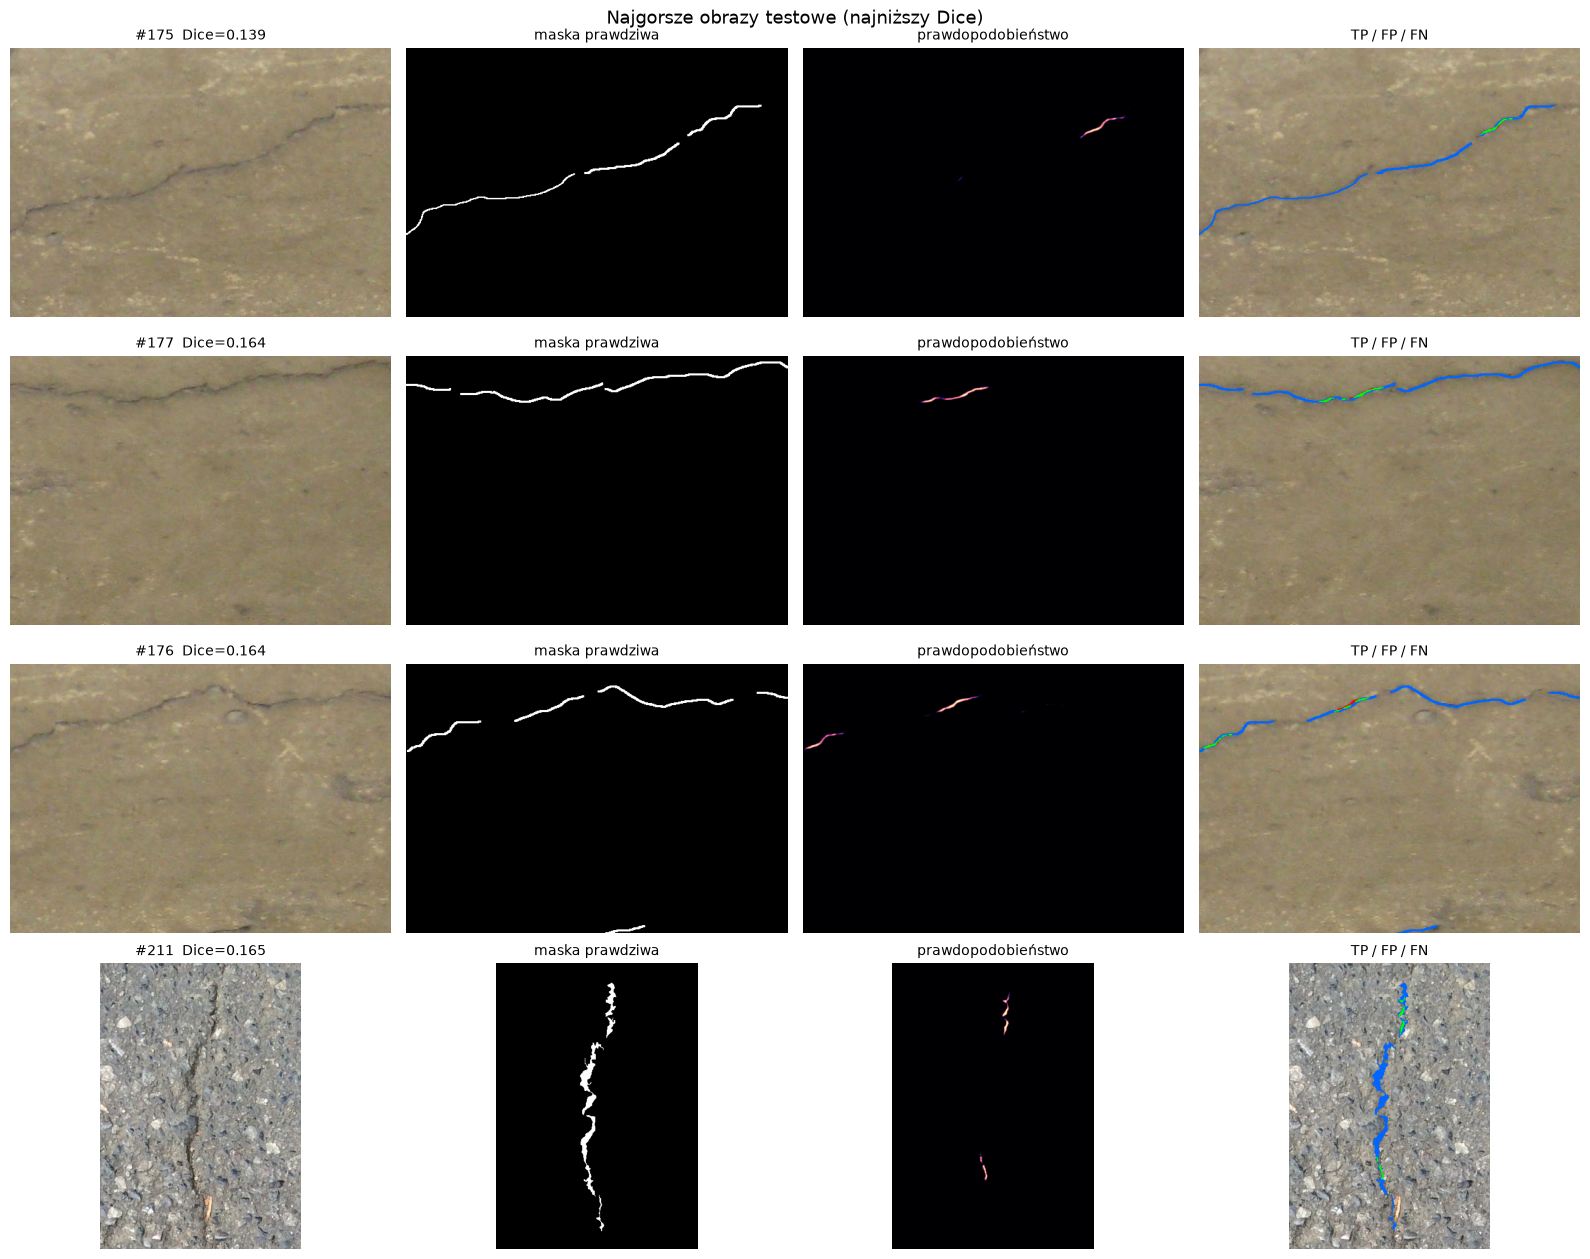

In [6]:
fig_worst = show_rows(worst_idx, "Najgorsze obrazy testowe (najniższy Dice)")
fig_worst.savefig(FIG_DIR / "predictions_worst.png", dpi=150, bbox_inches="tight")
plt.show()


In [ ]:
if LOG_TO_MLFLOW:
    from mlflow import MlflowClient
    client = MlflowClient(tracking_uri="sqlite:///mlflow.db")
    client.log_figure(RUN_ID, fig_random, "predictions/random.png")
    client.log_figure(RUN_ID, fig_worst, "predictions/worst.png")
    print("zalogowano do runu", RUN_ID)
else:
    print("rysunki zapisane w", FIG_DIR, "(LOG_TO_MLFLOW=False)")